# Импорты

In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import torch

from torchmin import minimize
from torchmin.benchmarks import rosen

import pandas as pd

# фиксируем seed для воспроизводимости батча
torch.manual_seed(42)

print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())

/home/aleksei/Documents/Development/LetiMaster/3_semester/NumericalMethodsForSolvingAppliedProblems/lab6/src/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch: 2.14.1+cu130
cuda available: True


# Функция Розенброка

/home/aleksei/Documents/Development/LetiMaster/3_semester/NumericalMethodsForSolvingAppliedProblems/lab6/src/.venv/lib/python3.14/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


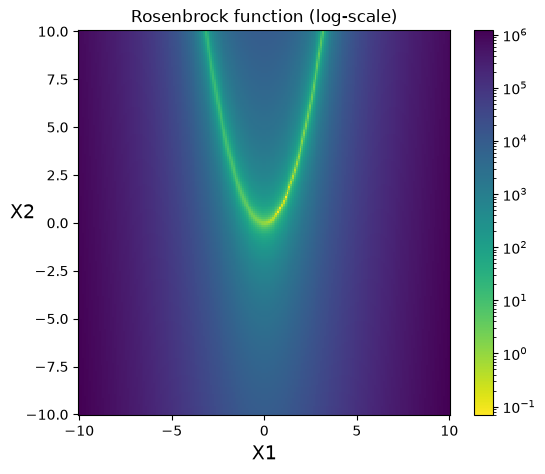

In [14]:
x, y = torch.meshgrid(
    torch.linspace(-10, 10, 200),
    torch.linspace(-10, 10, 200),
)
xy = torch.stack([x, y], -1)
z = rosen(xy, reduce=False)

fig, ax = plt.subplots(figsize=(6, 5))
c = ax.pcolormesh(x, y, z, shading='auto', cmap='viridis_r',
                  norm=LogNorm(vmin=z.min(), vmax=z.max()))
ax.set_xlabel('X1', fontsize=14)
ax.set_ylabel('X2', fontsize=14, rotation=0)
ax.yaxis.set_label_coords(-0.15, 0.5)
fig.colorbar(c, ax=ax)
plt.title("Rosenbrock function (log-scale)")
plt.show()

# Минимизация одной точки

## BFGS

In [15]:
x0 = torch.tensor([1., 8.])
print("f(x0) =", rosen(x0).item())

res_bfgs = minimize(
    rosen, x0,
    method='bfgs',
    options=dict(line_search='strong-wolfe'),
    max_iter=50,
    disp=2
)
print("\nfinal x:", res_bfgs.x)
print("final f:", rosen(res_bfgs.x).item())

f(x0) = 4900.0
initial fval: 4900.0000
iter   1 - fval: 119.3775
iter   2 - fval: 2.7829
iter   3 - fval: 2.7822
iter   4 - fval: 2.7819
iter   5 - fval: 2.7808
iter   6 - fval: 2.7784
iter   7 - fval: 2.7717
iter   8 - fval: 2.7548
iter   9 - fval: 2.7150
iter  10 - fval: 2.6417
iter  11 - fval: 2.5263
iter  12 - fval: 2.2811
iter  13 - fval: 1.8599
iter  14 - fval: 1.5437
iter  15 - fval: 1.1542
iter  16 - fval: 0.9849
iter  17 - fval: 0.8905
iter  18 - fval: 0.6474
iter  19 - fval: 0.5013
iter  20 - fval: 0.3446
iter  21 - fval: 0.2530
iter  22 - fval: 0.2189
iter  23 - fval: 0.1172
iter  24 - fval: 0.0974
iter  25 - fval: 0.0561
iter  26 - fval: 0.0329
iter  27 - fval: 0.0174
iter  28 - fval: 0.0111
iter  29 - fval: 0.0042
iter  30 - fval: 0.0010
iter  31 - fval: 0.0004
iter  32 - fval: 0.0000
iter  33 - fval: 0.0000
iter  34 - fval: 0.0000
iter  35 - fval: 0.0000
iter  36 - fval: 0.0000
Optimization terminated successfully.
         Current function value: 0.000000
         Iterat

## L-BFGS

In [16]:
res_lbfgs = minimize(
    rosen, x0,
    method='l-bfgs',
    options=dict(line_search='strong-wolfe'),
    max_iter=50,
    disp=2
)
print("\nfinal x:", res_lbfgs.x)
print("final f:", rosen(res_lbfgs.x).item())

initial fval: 4900.0000
iter   1 - fval: 119.3775
iter   2 - fval: 2.7829
iter   3 - fval: 2.7823
iter   4 - fval: 2.7822
iter   5 - fval: 2.7818
iter   6 - fval: 2.7810
iter   7 - fval: 2.7785
iter   8 - fval: 2.7723
iter   9 - fval: 2.7564
iter  10 - fval: 2.7188
iter  11 - fval: 2.6479
iter  12 - fval: 2.5357
iter  13 - fval: 2.3006
iter  14 - fval: 1.8822
iter  15 - fval: 1.5530
iter  16 - fval: 1.1887
iter  17 - fval: 1.0868
iter  18 - fval: 0.9367
iter  19 - fval: 0.6710
iter  20 - fval: 0.5970
iter  21 - fval: 0.4478
iter  22 - fval: 0.3348
iter  23 - fval: 0.2421
iter  24 - fval: 0.2027
iter  25 - fval: 0.1255
iter  26 - fval: 0.1022
iter  27 - fval: 0.0572
iter  28 - fval: 0.0445
iter  29 - fval: 0.0167
iter  30 - fval: 0.0119
iter  31 - fval: 0.0054
iter  32 - fval: 0.0024
iter  33 - fval: 0.0007
iter  34 - fval: 0.0001
iter  35 - fval: 0.0000
iter  36 - fval: 0.0000
iter  37 - fval: 0.0000
iter  38 - fval: 0.0000
Optimization terminated successfully.
         Current functio

## Newton-CG

In [17]:
res_ncg = minimize(
    rosen, x0,
    method='newton-cg',
    options=dict(line_search='strong-wolfe'),
    max_iter=50,
    disp=2
)
print("\nfinal x:", res_ncg.x)
print("final f:", rosen(res_ncg.x).item())

initial fval: 4900.0000
iter   1 - fval: 6.0505
iter   2 - fval: 2.8156
iter   3 - fval: 2.8144
iter   4 - fval: 2.3266
iter   5 - fval: 2.1088
iter   6 - fval: 1.7060
iter   7 - fval: 1.5851
iter   8 - fval: 1.2548
iter   9 - fval: 1.1625
iter  10 - fval: 0.8967
iter  11 - fval: 0.8249
iter  12 - fval: 0.6160
iter  13 - fval: 0.5591
iter  14 - fval: 0.4051
iter  15 - fval: 0.3299
iter  16 - fval: 0.2217
iter  17 - fval: 0.1886
iter  18 - fval: 0.1167
iter  19 - fval: 0.0987
iter  20 - fval: 0.0543
iter  21 - fval: 0.0442
iter  22 - fval: 0.0210
iter  23 - fval: 0.0118
iter  24 - fval: 0.0035
iter  25 - fval: 0.0021
iter  26 - fval: 0.0005
iter  27 - fval: 0.0000
iter  28 - fval: 0.0000
iter  29 - fval: 0.0000
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 29
         Function evaluations: 85
         CG iterations: 41

final x: tensor([1.0000, 1.0000])
final f: 7.817391178832622e-11


## Newton-Exact (с регуляризацией Тихонова)

In [19]:
res_ne = minimize(
    rosen, x0,
    method='newton-exact',
    options=dict(line_search='strong-wolfe', tikhonov=1e-4),
    max_iter=50,
    disp=2
)
print("\nfinal x:", res_ne.x)
print("final f:", rosen(res_ne.x).item())

initial fval: 4900.0000
iter   1 - fval: 3.3641 - info: 1
iter   2 - fval: 2.8111 - info: 2
iter   3 - fval: 2.3209 - info: 0
iter   4 - fval: 1.7723 - info: 0
iter   5 - fval: 1.4215 - info: 0
iter   6 - fval: 0.9833 - info: 0
iter   7 - fval: 0.7774 - info: 0
iter   8 - fval: 0.5245 - info: 0
iter   9 - fval: 0.3976 - info: 0
iter  10 - fval: 0.2116 - info: 0
iter  11 - fval: 0.1417 - info: 0
iter  12 - fval: 0.0715 - info: 0
iter  13 - fval: 0.0381 - info: 0
iter  14 - fval: 0.0113 - info: 0
iter  15 - fval: 0.0046 - info: 0
iter  16 - fval: 0.0002 - info: 0
iter  17 - fval: 0.0000 - info: 0
iter  18 - fval: 0.0000 - info: 0
iter  19 - fval: 0.0000 - info: 0
iter  20 - fval: 0.0000 - info: 0
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 20
         Function evaluations: 58

final x: tensor([1., 1.])
final f: 0.0


# Батч из 4 точек

## BFGS

In [20]:
torch.manual_seed(337)
x0_batch = torch.randn(4, 2)
print("f(x0_batch) =", rosen(x0_batch).item())

res_bfgs_b = minimize(
    rosen, x0_batch,
    method='bfgs',
    options=dict(line_search='strong-wolfe'),
    max_iter=50,
    disp=2
)
print("\nfinal x:\n", res_bfgs_b.x)

f(x0_batch) = 602.9989013671875
initial fval: 602.9989
iter   1 - fval: 339.5845
iter   2 - fval: 95.0195
iter   3 - fval: 26.4602
iter   4 - fval: 12.5725
iter   5 - fval: 5.1806
iter   6 - fval: 5.1081
iter   7 - fval: 5.0820
iter   8 - fval: 5.0424
iter   9 - fval: 4.9870
iter  10 - fval: 4.9093
iter  11 - fval: 4.7990
iter  12 - fval: 4.6148
iter  13 - fval: 4.3063
iter  14 - fval: 3.8509
iter  15 - fval: 3.3909
iter  16 - fval: 3.1421
iter  17 - fval: 2.8380
iter  18 - fval: 2.4118
iter  19 - fval: 2.1209
iter  20 - fval: 1.9240
iter  21 - fval: 1.6039
iter  22 - fval: 1.3444
iter  23 - fval: 1.1244
iter  24 - fval: 0.9569
iter  25 - fval: 0.7342
iter  26 - fval: 0.6449
iter  27 - fval: 0.5003
iter  28 - fval: 0.4138
iter  29 - fval: 0.3442
iter  30 - fval: 0.2815
iter  31 - fval: 0.2140
iter  32 - fval: 0.1431
iter  33 - fval: 0.1233
iter  34 - fval: 0.1004
iter  35 - fval: 0.0827
iter  36 - fval: 0.0740
iter  37 - fval: 0.0650
iter  38 - fval: 0.0591
iter  39 - fval: 0.0577
iter

## L-BFGS

In [21]:
res_lbfgs_b = minimize(
    rosen, x0_batch,
    method='l-bfgs',
    options=dict(line_search='strong-wolfe'),
    max_iter=50,
    disp=2
)
print("\nfinal x:\n", res_lbfgs_b.x)

initial fval: 602.9989
iter   1 - fval: 339.5845
iter   2 - fval: 95.0195
iter   3 - fval: 21.5655
iter   4 - fval: 5.2430
iter   5 - fval: 4.9395
iter   6 - fval: 4.9042
iter   7 - fval: 4.8668
iter   8 - fval: 4.7709
iter   9 - fval: 4.6042
iter  10 - fval: 4.2993
iter  11 - fval: 3.7640
iter  12 - fval: 3.0566
iter  13 - fval: 3.0339
iter  14 - fval: 2.3893
iter  15 - fval: 2.2195
iter  16 - fval: 2.0010
iter  17 - fval: 1.5127
iter  18 - fval: 1.2743
iter  19 - fval: 1.0382
iter  20 - fval: 0.8332
iter  21 - fval: 0.7181
iter  22 - fval: 0.5823
iter  23 - fval: 0.4413
iter  24 - fval: 0.3278
iter  25 - fval: 0.2648
iter  26 - fval: 0.1781
iter  27 - fval: 0.1088
iter  28 - fval: 0.0633
iter  29 - fval: 0.0492
iter  30 - fval: 0.0307
iter  31 - fval: 0.0208
iter  32 - fval: 0.0143
iter  33 - fval: 0.0130
iter  34 - fval: 0.0119
iter  35 - fval: 0.0119
iter  36 - fval: 0.0118
iter  37 - fval: 0.0114
iter  38 - fval: 0.0108
iter  39 - fval: 0.0091
iter  40 - fval: 0.0060
iter  41 - fv

## Newton-CG

In [22]:
res_ncg_b = minimize(
    rosen, x0_batch,
    method='newton-cg',
    options=dict(line_search='strong-wolfe'),
    max_iter=50,
    disp=2
)
print("\nfinal x:\n", res_ncg_b.x)
print("\ndist to (1,1):", (res_ncg_b.x - 1).norm(dim=1))

initial fval: 602.9989
iter   1 - fval: 367.2567
iter   2 - fval: 47.2528
iter   3 - fval: 17.9457
iter   4 - fval: 5.0277
iter   5 - fval: 4.5732
iter   6 - fval: 4.2605
iter   7 - fval: 3.5691
iter   8 - fval: 3.1882
iter   9 - fval: 3.0478
iter  10 - fval: 2.9619
iter  11 - fval: 2.5264
iter  12 - fval: 2.1677
iter  13 - fval: 1.8351
iter  14 - fval: 1.7114
iter  15 - fval: 1.3834
iter  16 - fval: 1.1907
iter  17 - fval: 0.8378
iter  18 - fval: 0.7662
iter  19 - fval: 0.5443
iter  20 - fval: 0.4112
iter  21 - fval: 0.2527
iter  22 - fval: 0.2030
iter  23 - fval: 0.1118
iter  24 - fval: 0.0870
iter  25 - fval: 0.0403
iter  26 - fval: 0.0301
iter  27 - fval: 0.0104
iter  28 - fval: 0.0071
iter  29 - fval: 0.0023
iter  30 - fval: 0.0000
iter  31 - fval: 0.0000
iter  32 - fval: 0.0000
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 32
         Function evaluations: 84
         CG iterations: 44

final x:
 tensor([[1.0000, 1.0000],
   

## Newton-Exact

In [23]:
res_ne_b = minimize(
    rosen, x0_batch,
    method='newton-exact',
    options=dict(line_search='strong-wolfe', tikhonov=1e-4),
    max_iter=50,
    disp=2
)
print("\nfinal x:\n", res_ne_b.x)

initial fval: 602.9989
iter   1 - fval: 172.6960 - info: 1
iter   2 - fval: 7.9165 - info: 2
iter   3 - fval: 4.1152 - info: 4
iter   4 - fval: 3.8578 - info: 2
iter   5 - fval: 3.7776 - info: 8
iter   6 - fval: 3.7623 - info: 8
iter   7 - fval: 3.6951 - info: 8
iter   8 - fval: 3.6450 - info: 8
iter   9 - fval: 3.6095 - info: 8
iter  10 - fval: 3.5703 - info: 2
iter  11 - fval: 3.5536 - info: 8
iter  12 - fval: 3.5152 - info: 2
iter  13 - fval: 3.4937 - info: 8
iter  14 - fval: 3.4614 - info: 2
iter  15 - fval: 3.4361 - info: 8
iter  16 - fval: 3.4105 - info: 2
iter  17 - fval: 3.3857 - info: 8
iter  18 - fval: 3.3606 - info: 2
iter  19 - fval: 3.3361 - info: 8
iter  20 - fval: 3.3114 - info: 2
iter  21 - fval: 3.2872 - info: 8
iter  22 - fval: 3.2627 - info: 2
iter  23 - fval: 3.2388 - info: 8
iter  24 - fval: 3.2146 - info: 2
iter  25 - fval: 3.1909 - info: 8
iter  26 - fval: 3.1670 - info: 2
iter  27 - fval: 3.1435 - info: 8
iter  28 - fval: 3.1198 - info: 2
iter  29 - fval: 3.0966

# Визуализация траекторий Newton-CG и Newton-Exact из одной точки

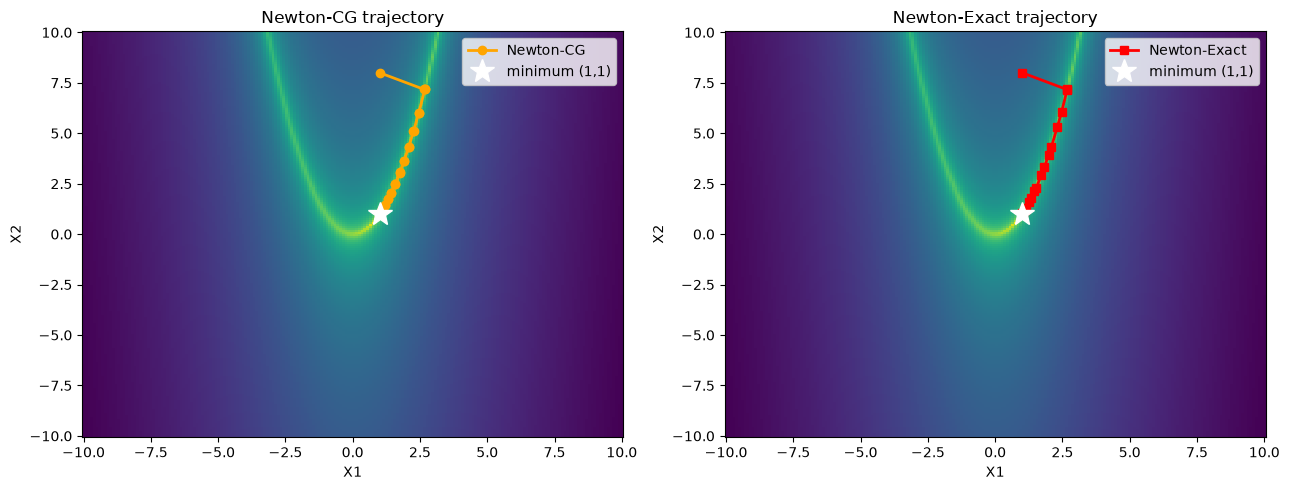

In [13]:
def run_with_trace(method, x0, **opts):
    traj = [x0.detach().clone()]
    def cb(x):
        traj.append(x.detach().clone())
    res = minimize(rosen, x0, method=method, options=opts,
                   max_iter=50, disp=0, callback=cb)
    return res, torch.stack(traj)

x0 = torch.tensor([1., 8.])
_, traj_ncg = run_with_trace('newton-cg', x0, line_search='strong-wolfe')
_, traj_ne  = run_with_trace('newton-exact', x0,
                             line_search='strong-wolfe', tikhonov=1e-4)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- левый график: Newton-CG ---
ax = axes[0]
ax.pcolormesh(x, y, z, shading='auto', cmap='viridis_r',
              norm=LogNorm(vmin=z.min(), vmax=z.max()))
ax.plot(traj_ncg[:, 0], traj_ncg[:, 1], 'o-', color='orange',
        label='Newton-CG', lw=2, markersize=6)
ax.plot(1, 1, 'w*', markersize=18, label='minimum (1,1)')
ax.set_xlabel('X1'); ax.set_ylabel('X2')
ax.set_title("Newton-CG trajectory")
ax.legend()

# --- правый график: Newton-Exact ---
ax = axes[1]
ax.pcolormesh(x, y, z, shading='auto', cmap='viridis_r',
              norm=LogNorm(vmin=z.min(), vmax=z.max()))
ax.plot(traj_ne[:, 0], traj_ne[:, 1], 's-', color='red',
        label='Newton-Exact', lw=2, markersize=6)
ax.plot(1, 1, 'w*', markersize=18, label='minimum (1,1)')
ax.set_xlabel('X1'); ax.set_ylabel('X2')
ax.set_title("Newton-Exact trajectory")
ax.legend()

plt.tight_layout()
plt.show()

# Сводная таблица

In [12]:
def summarize(name, res):
    return {
        "method": name,
        "iter": getattr(res, "nit", None) or getattr(res, "n_iter", None),
        "f_final": float(rosen(res.x)),
        "||x - 1||": float((res.x - 1).norm()),
    }

rows = [
    summarize("bfgs (1pt)",        res_bfgs),
    summarize("l-bfgs (1pt)",      res_lbfgs),
    summarize("newton-cg (1pt)",   res_ncg),
    summarize("newton-exact (1pt)",res_ne),
    summarize("bfgs (batch)",      res_bfgs_b),
    summarize("l-bfgs (batch)",    res_lbfgs_b),
    summarize("newton-cg (batch)", res_ncg_b),
    summarize("newton-exact (batch)", res_ne_b),
]
df = pd.DataFrame(rows)
print(df.to_string(index=False))

              method  iter      f_final  ||x - 1||
          bfgs (1pt)    36 2.900435e-09   0.000104
        l-bfgs (1pt)    38 1.398490e-10   0.000022
     newton-cg (1pt)    29 7.817391e-11   0.000020
  newton-exact (1pt)    20 0.000000e+00   0.000000
        bfgs (batch)    50 2.516910e-02   0.344770
      l-bfgs (batch)    50 3.539758e-06   0.004207
   newton-cg (batch)    32 3.035964e-09   0.000123
newton-exact (batch)    50 2.623368e+00   2.243044
